# 03 · Aprendizaje no supervisado — Días típicos de demanda

**Proyecto:** Forecast de demanda eléctrica del Mercado Eléctrico Mayorista (MEM) argentino.

**Etapa:** Pre-entrega 4 — clustering.

## Pregunta

En el EDA vimos que la forma de la curva diaria de demanda cambia según el día de la semana y la estación: el pico es de tarde en verano y de noche en invierno, y los fines de semana la curva es más baja y plana. Pero esas categorías las pusimos nosotros.

**¿Qué "tipos de día" aparecen si dejamos que los datos se agrupen solos, sin decirles qué es hábil, feriado, verano o invierno?** Y además: **¿qué días no se parecen a ningún otro?**

Para el operador las dos respuestas sirven. Los días típicos son los perfiles de carga que tiene que saber programar. Los días atípicos son los que un modelo entrenado con días "normales" va a predecir peor.

## Decisiones de diseño

| Decisión | Elección | Por qué |
|---|---|---|
| Unidad de análisis | Cada **día** es un punto, descrito por sus **24 demandas horarias** | Lo que queremos agrupar es la curva de carga de un día completo. |
| Normalización | Dividir cada hora por el **promedio de ese día** | Se agrupa por **forma**, no por nivel. Sin esto, K-means separaría sobre todo días de mucha y poca demanda, y la tendencia de crecimiento (2026 > 2021) contaminaría los grupos. |
| Algoritmo principal | **K-means**, eligiendo k con el codo y la silueta | Simple, interpretable: cada grupo se resume con su curva promedio (centroide). |
| Comparación | **DBSCAN** | No necesita fijar k y marca como **ruido** los puntos que no pertenecen a ninguna zona densa: sirve para encontrar días atípicos. |
| Visualización | **PCA** (basado en SVD) a 2 dimensiones | Para ver en un plano un espacio de 24 dimensiones. |
| Variables que **no** entran al clustering | Tipo de día, mes, temperatura | Se usan **después**, para interpretar los grupos. Si entraran, el clustering "encontraría" lo que ya le dijimos. |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = BASE / "data" / "processed"
FIG = BASE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# semilla fija para que los resultados sean reproducibles
SEMILLA = 42


def guardar(nombre):
    """Muestra el gráfico actual y lo guarda en reports/figures."""
    plt.tight_layout()
    plt.savefig(FIG / f"03_{nombre}.png", bbox_inches="tight")
    plt.show()

## 1. De la serie horaria a una matriz de días

Se parte de la misma serie horaria del MEM de las etapas anteriores (2021 → jul-2026, sin huecos) y se reorganiza: una **fila por día** y una **columna por hora** (0 a 23).

In [2]:
demanda = pd.read_csv(DATA / "demanda_horaria_mem.csv", parse_dates=["timestamp"])
temperatura = pd.read_csv(DATA / "temperatura_horaria_ba.csv", parse_dates=["timestamp"])
demanda["fecha"] = demanda.timestamp.dt.normalize()
demanda["hora"] = demanda.timestamp.dt.hour

# matriz días x horas
curvas = demanda.pivot(index="fecha", columns="hora", values="demanda_mwh")
print(f"Matriz: {curvas.shape[0]:,} días x {curvas.shape[1]} horas | valores faltantes: {curvas.isna().sum().sum()}")

# información de cada día que NO entra al clustering: se usa después para interpretar los grupos
temp_dia = temperatura.groupby(temperatura.timestamp.dt.normalize())["temperatura_c"].agg(["mean", "max"])
info = pd.DataFrame({
    "tipo_dia": demanda.groupby("fecha")["tipo_dia"].first(),
    "demanda_media": curvas.mean(axis=1),
    "temp_media": temp_dia["mean"],
    "temp_max": temp_dia["max"],
})
info["mes"] = info.index.month
info["dia_semana"] = info.index.dayofweek
info.head()

Matriz: 2,038 días x 24 horas | valores faltantes: 0


,tipo_dia,demanda_media,temp_media,temp_max,mes,dia_semana
2021-01-01,no_habil,12852.377917,25.033333,30.4,1,4
2021-01-02,no_habil,15663.056625,25.758333,30.6,1,5
2021-01-03,no_habil,14930.616292,25.425000,28.2,1,6
2021-01-04,habil,16777.803292,24.675000,27.0,1,0
2021-01-05,habil,16518.735542,23.887500,28.0,1,1


## 2. Normalización: forma, no nivel

Cada fila se divide por el promedio de su día. Un valor de 1,2 a las 15 h significa "a esa hora se demanda 20 % más que el promedio del día".

El gráfico muestra por qué hace falta: un día hábil de invierno y uno de verano tienen niveles distintos, pero lo que más los diferencia es la **forma** (dónde está el pico). Después de normalizar, las dos curvas quedan en la misma escala y la comparación es solo de forma.

No se usa `StandardScaler` por columna: las 24 columnas ya están en la misma unidad, y estandarizar cada hora por separado le daría el mismo peso a la madrugada (que varía poco entre días) que a las horas de pico, deformando las curvas.

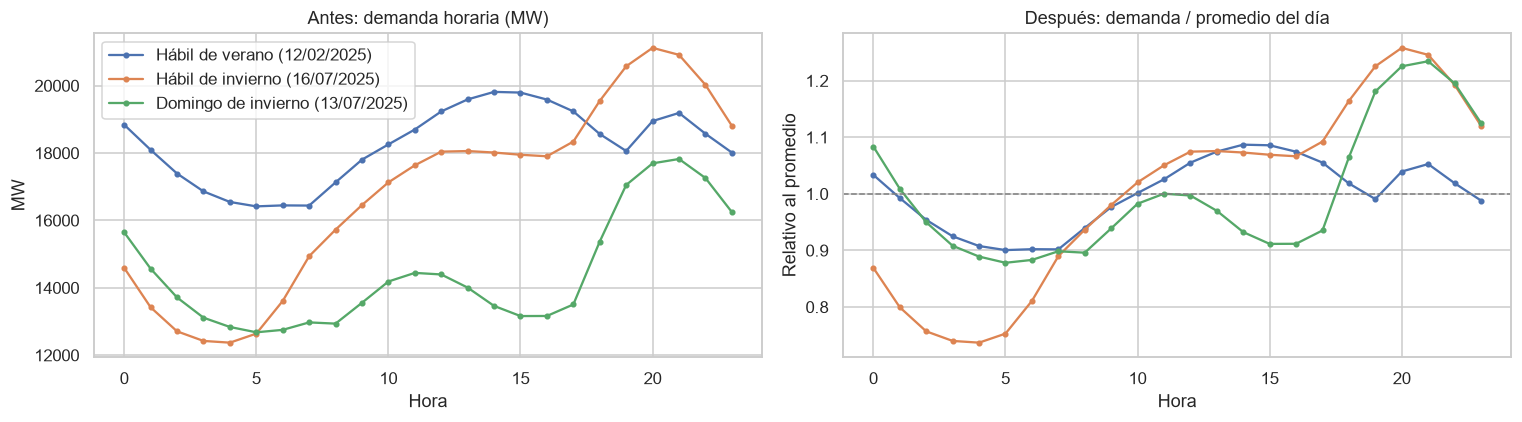

In [3]:
formas = curvas.div(curvas.mean(axis=1), axis=0)

ejemplos = {"Hábil de verano (12/02/2025)": "2025-02-12", "Hábil de invierno (16/07/2025)": "2025-07-16",
            "Domingo de invierno (13/07/2025)": "2025-07-13"}
# control: cada ejemplo tiene que ser del tipo de día que dice su etiqueta
for etiqueta, fecha in ejemplos.items():
    esperado = "no_habil" if etiqueta.startswith("Domingo") else "habil"
    assert info.loc[fecha, "tipo_dia"] == esperado, f"{etiqueta}: el día es {info.loc[fecha, 'tipo_dia']}"

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for etiqueta, fecha in ejemplos.items():
    axes[0].plot(curvas.loc[fecha].values, marker=".", label=etiqueta)
    axes[1].plot(formas.loc[fecha].values, marker=".", label=etiqueta)
axes[0].set(title="Antes: demanda horaria (MW)", xlabel="Hora", ylabel="MW")
axes[1].set(title="Después: demanda / promedio del día", xlabel="Hora", ylabel="Relativo al promedio")
axes[1].axhline(1, color="gray", lw=1, ls="--")
axes[0].legend()
guardar("normalizacion_curvas")

## 3. K-means: ¿cuántos grupos?

K-means necesita que le digamos **k**, la cantidad de grupos. Se prueban valores de 2 a 8 con dos criterios:

- **Método del codo (inercia):** la suma de distancias de cada día a su centroide. Siempre baja al agregar grupos; se busca el punto donde deja de bajar mucho, el "codo".
- **Coeficiente de silueta:** para cada día compara qué tan cerca está de su propio grupo contra el grupo vecino más cercano. Va de −1 a 1; más alto es mejor. Valores de 0,25 a 0,5 indican una estructura razonable, con grupos que se tocan en los bordes.
- **Davies-Bouldin** como tercer control: mide cuánto se superponen los grupos; más bajo es mejor.

`n_init=10` corre K-means 10 veces con centroides iniciales distintos y se queda con la mejor, porque el resultado depende del punto de partida.

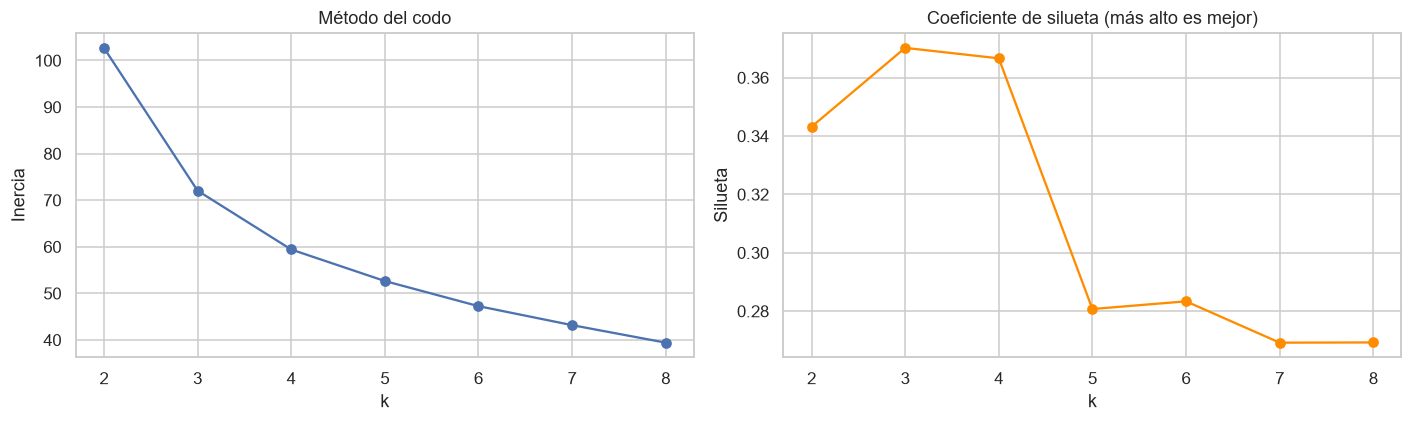

,inercia,silueta,davies_bouldin
k,,,
2,102.715,0.343,1.245
3,72.051,0.370,1.059
4,59.415,0.367,1.114
5,52.646,0.281,1.174
6,47.251,0.283,1.194
7,43.170,0.269,1.185
8,39.409,0.269,1.234


In [4]:
evaluacion_k = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(formas)
    evaluacion_k.append({
        "k": k,
        "inercia": km.inertia_,
        "silueta": silhouette_score(formas, km.labels_),
        "davies_bouldin": davies_bouldin_score(formas, km.labels_),
    })
evaluacion_k = pd.DataFrame(evaluacion_k).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
evaluacion_k["inercia"].plot(ax=axes[0], marker="o")
axes[0].set(title="Método del codo", xlabel="k", ylabel="Inercia")
evaluacion_k["silueta"].plot(ax=axes[1], marker="o", color="darkorange")
axes[1].set(title="Coeficiente de silueta (más alto es mejor)", xlabel="k", ylabel="Silueta")
guardar("eleccion_k")
evaluacion_k.round(3)

**Se elige k = 4.**

- La silueta es máxima en k = 3 (0,370), pero k = 4 está prácticamente empatado (0,367). A partir de k = 5 cae claramente (0,28), señal de que se empiezan a partir grupos naturales.
- El codo de la inercia está entre 3 y 4: de 3 a 4 todavía baja bastante (72 → 59) y después baja cada vez menos.
- Entre dos opciones casi iguales en las métricas, se elige la más **interpretable**. En la sección siguiente se ve que k = 4 separa justo los dos ejes que el EDA mostraba como importantes: hábil o no hábil, y verano o invierno. Con k = 3 el verano queda como un solo grupo que mezcla días hábiles y no hábiles, y los fines de semana de todo el año quedan juntos.

Una silueta de ~0,37 indica grupos **reales pero que se tocan en los bordes**. Tiene sentido: entre el invierno y el verano hay un otoño y una primavera, y los días de transición no pertenecen claramente a ningún grupo.

## 4. Los días típicos

Se entrena K-means con el k elegido. Para que los nombres de los grupos no dependan de cómo los numera el algoritmo, se les pone nombre con una regla a partir de su composición:

- **hábil / no hábil:** según qué tipo de día (de CAMMESA) es mayoría en el grupo;
- **verano / invierno:** según si la mayoría de sus días cae entre noviembre y marzo (temporada de calor) o no.

El tipo de día y el mes **no se usaron para agrupar**; se usan recién ahora, para ponerle nombre a lo que encontró el algoritmo.

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(formas)
info["cluster"] = kmeans.labels_

MESES_CALOR = [11, 12, 1, 2, 3]


def nombre_grupo(dias):
    """Nombra un grupo por su composición: tipo de día mayoritario y temporada mayoritaria."""
    tipo = "Hábil" if (dias["tipo_dia"] == "habil").mean() > 0.5 else "No hábil"
    temporada = "verano" if dias["mes"].isin(MESES_CALOR).mean() > 0.5 else "invierno"
    return f"{tipo} de {temporada}"


nombres = {c: nombre_grupo(dias) for c, dias in info.groupby("cluster")}
assert len(set(nombres.values())) == K, f"dos grupos recibieron el mismo nombre: {nombres}"
info["grupo"] = info["cluster"].map(nombres)
ORDEN = sorted(nombres.values())
COLORES = dict(zip(ORDEN, sns.color_palette("tab10", K)))

info["grupo"].value_counts().reindex(ORDEN).rename("días")

grupo
Hábil de invierno       847
Hábil de verano         480
No hábil de invierno    428
No hábil de verano      283
Name: días, dtype: int64

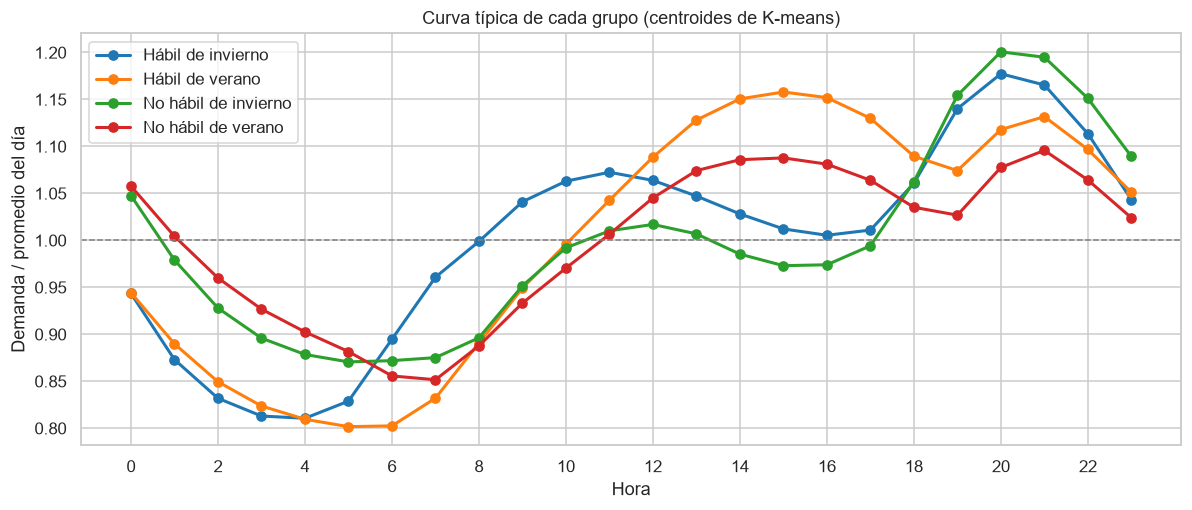

In [6]:
# centroides: la curva típica de cada grupo
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=range(24)).rename(index=nombres)

fig, ax = plt.subplots(figsize=(11, 4.8))
for grupo in ORDEN:
    ax.plot(centroides.loc[grupo].values, marker="o", lw=2, color=COLORES[grupo], label=grupo)
ax.axhline(1, color="gray", lw=1, ls="--")
ax.set(title="Curva típica de cada grupo (centroides de K-means)", xlabel="Hora", ylabel="Demanda / promedio del día", xticks=range(0, 24, 2))
ax.legend()
guardar("centroides_kmeans")

Las cuatro curvas típicas cuentan la historia del consumo eléctrico argentino:

- **Hábil de verano:** el pico está a la **tarde (14–16 h)**, el momento de más calor, por el aire acondicionado. La madrugada es la más baja de todas (0,80 del promedio).
- **Hábil de invierno:** **dos picos**, uno a la mañana (~11 h, actividad comercial e industrial) y otro más alto a la noche (~20 h, iluminación y calefacción residencial).
- **No hábil de invierno:** sin el pico de la mañana (no hay actividad laboral), con el pico de la noche más pronunciado de todos (1,20 del promedio).
- **No hábil de verano:** la curva más **plana**. Sube a la tarde por el calor, pero menos que un día hábil, y su madrugada es relativamente alta: la gente se acuesta más tarde y el aire acondicionado queda prendido de noche.

Es la interacción **hora × estación** que el EDA había mostrado y que justificó usar modelos de árboles en el notebook 02. Acá aparece sola, sin decirle al algoritmo qué mes era cada día.

## 5. ¿Qué hay dentro de cada grupo?

Ahora se cruzan los grupos con la información que el algoritmo **no vio**: tipo de día, día de la semana, mes y temperatura. Si los grupos tienen sentido físico, estas variables deberían explicarlos.

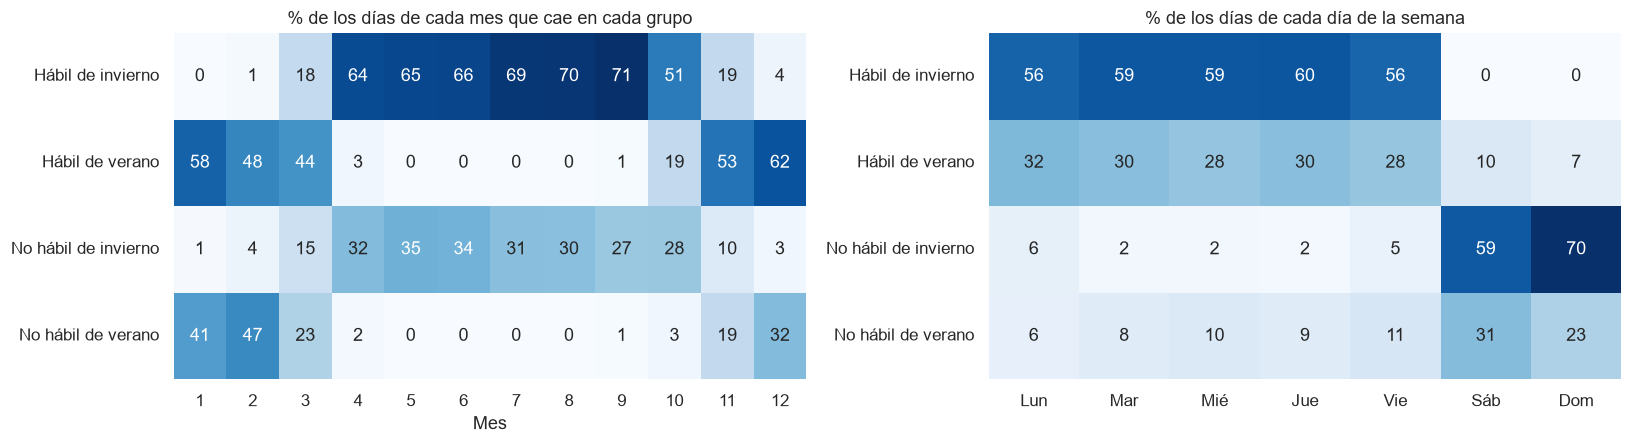

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
por_mes = pd.crosstab(info["grupo"], info["mes"], normalize="columns").reindex(ORDEN) * 100
sns.heatmap(por_mes, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="% de los días de cada mes que cae en cada grupo", xlabel="Mes", ylabel="")
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_dia = pd.crosstab(info["grupo"], info["dia_semana"], normalize="columns").reindex(ORDEN) * 100
por_dia.columns = dias
sns.heatmap(por_dia, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set(title="% de los días de cada día de la semana", xlabel="", ylabel="")
guardar("grupos_mes_dia_semana")

In [8]:
# perfil de cada grupo con las variables que no entraron al clustering
resumen = info.groupby("grupo").agg(
    dias=("cluster", "size"),
    pct_habiles=("tipo_dia", lambda s: (s == "habil").mean() * 100),
    temp_media=("temp_media", "mean"),
    temp_max=("temp_max", "mean"),
    demanda_media_MW=("demanda_media", "mean"),
).reindex(ORDEN)
resumen.round(1)

,dias,pct_habiles,temp_media,temp_max,demanda_media_MW
grupo,,,,,
Hábil de invierno,847,99.1,14.0,17.5,15959.1
Hábil de verano,480,86.7,23.9,28.1,17264.5
No hábil de invierno,428,0.2,14.5,18.2,14103.9
No hábil de verano,283,37.8,23.6,27.1,16507.7


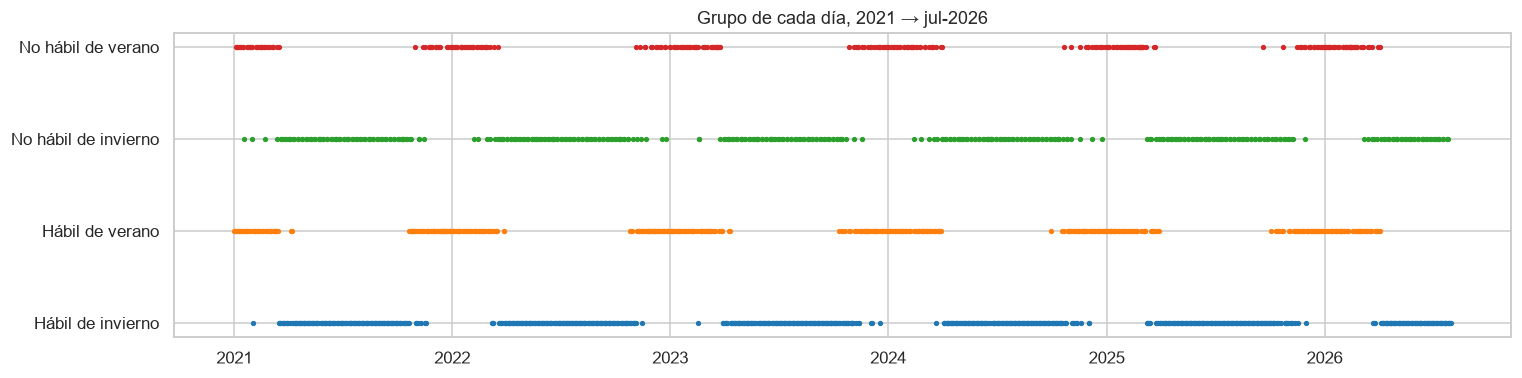

In [9]:
# los grupos a lo largo del tiempo: cada punto es un día
fig, ax = plt.subplots(figsize=(14, 3.6))
for grupo in ORDEN:
    sel = info[info["grupo"] == grupo]
    ax.scatter(sel.index, [ORDEN.index(grupo)] * len(sel), s=6, color=COLORES[grupo])
ax.set(yticks=range(K), yticklabels=ORDEN, title="Grupo de cada día, 2021 → jul-2026", xlabel="")
guardar("grupos_en_el_tiempo")

**Los grupos tienen sentido físico, y el algoritmo no vio ni el mes, ni el día de la semana, ni la temperatura.**

- **Hábil / no hábil:** los dos grupos "no hábiles" juntan el 90 % de los sábados y el 93 % de los domingos. El grupo hábil de invierno tiene un 99,1 % de días hábiles.
- **Verano / invierno:** el corte lo marca la **temperatura**, no el calendario. Los grupos de verano tienen ~24 °C de temperatura media contra ~14 °C de los de invierno. Por eso marzo, octubre y noviembre aparecen repartidos: son meses de transición, y un día de octubre caluroso ya se comporta como uno de verano.
- **El grupo "No hábil de verano" no es solo fines de semana:** el 38 % de sus días son hábiles, casi todos de enero y febrero. Son días laborables de vacaciones de verano, con menos actividad, cuya curva se parece más a la de un fin de semana que a la de un día hábil normal. CAMMESA los clasifica como hábiles, pero el consumo dice otra cosa.
- **Nivel:** aunque se agrupó por forma, los grupos de verano tienen más demanda media (17.300 MW los días hábiles) que los de invierno (16.000 MW). El calor mueve más la demanda que el frío, como se vio en el EDA.

En el gráfico temporal se ve el ritmo de las estaciones año tras año, sin cambios de régimen: los tipos de día se repiten de forma estable de 2021 a 2026.

## 6. Visualización con PCA

Cada día vive en un espacio de 24 dimensiones, imposible de graficar. El **Análisis de Componentes Principales (PCA)** busca las direcciones en las que los días más se diferencian entre sí y proyecta los datos sobre ellas. Internamente se calcula con la **descomposición en valores singulares (SVD)** de la matriz de días.

Además de dibujar, las componentes se pueden **interpretar**: cada una es una "forma de desviarse" de la curva promedio.

Varianza explicada por las primeras componentes: [46.  32.9 15.9  1.8] %
PC1 + PC2: 78.8%


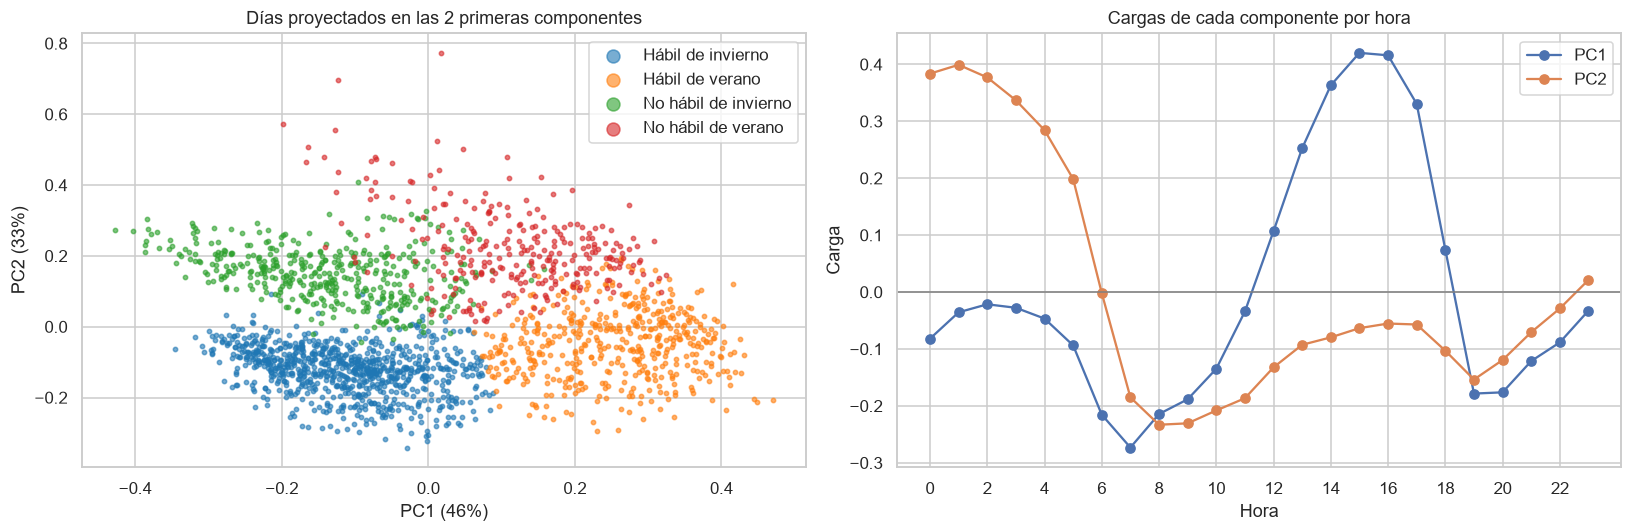

In [10]:
pca = PCA(random_state=SEMILLA).fit(formas)
coordenadas = pd.DataFrame(pca.transform(formas)[:, :2], index=formas.index, columns=["PC1", "PC2"])
varianza = pca.explained_variance_ratio_
print("Varianza explicada por las primeras componentes:", (varianza[:4] * 100).round(1), "%")
print(f"PC1 + PC2: {varianza[:2].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for grupo in ORDEN:
    sel = coordenadas[info["grupo"] == grupo]
    axes[0].scatter(sel.PC1, sel.PC2, s=8, alpha=0.6, color=COLORES[grupo], label=grupo)
axes[0].set(title="Días proyectados en las 2 primeras componentes", xlabel=f"PC1 ({varianza[0]:.0%})", ylabel=f"PC2 ({varianza[1]:.0%})")
axes[0].legend(markerscale=3)
# cargas: cuánto pesa cada hora en cada componente
axes[1].plot(pca.components_[0], marker="o", label="PC1")
axes[1].plot(pca.components_[1], marker="o", label="PC2")
axes[1].axhline(0, color="gray", lw=1)
axes[1].set(title="Cargas de cada componente por hora", xlabel="Hora", ylabel="Carga", xticks=range(0, 24, 2))
axes[1].legend()
guardar("pca_grupos")

**Dos componentes explican el 79 % de la variación** entre las formas de los días, y cada una tiene una lectura clara:

- **PC1 (46 %) = "pico de la tarde".** Carga positiva fuerte entre las 13 y las 17 h y negativa a la mañana temprano y a la noche. Un día con PC1 alta tiene un pico de tarde marcado: es el eje **verano ↔ invierno**. En el gráfico, los dos grupos de verano están a la derecha.
- **PC2 (33 %) = "madrugada alta, mañana baja".** Carga positiva de 0 a 5 h y negativa de 7 a 11 h. Un día con PC2 alta tiene noches relativamente altas y mañanas sin actividad: es el eje **no hábil ↔ hábil**. Los dos grupos no hábiles están arriba.

PCA y K-means llegan a la misma conclusión por caminos distintos: **las curvas diarias se organizan en dos ejes, la estación y la actividad laboral**. Los cuatro grupos de K-means son los cuatro cuadrantes de ese plano.

También se ve por qué la silueta es moderada: los puntos forman una **nube continua**, sin huecos entre los grupos.

## 7. Comparación: DBSCAN

DBSCAN agrupa de otra forma: un grupo es una **zona densa** de puntos, y los puntos que quedan en zonas poco densas se marcan como **ruido** (etiqueta −1). Tiene dos parámetros:

- `min_samples`: cuántos vecinos necesita un punto para ser "núcleo" de un grupo. Se usa 10.
- `eps`: el radio dentro del cual se buscan esos vecinos. Es el parámetro delicado.

Para elegir `eps` se usa el **gráfico de k-distancias**: para cada día, la distancia a su 10º vecino más cercano, ordenada de menor a mayor. La mayoría de los días tiene vecinos cerca; donde la curva se dispara están los días aislados. El `eps` conviene ponerlo en esa zona de quiebre.

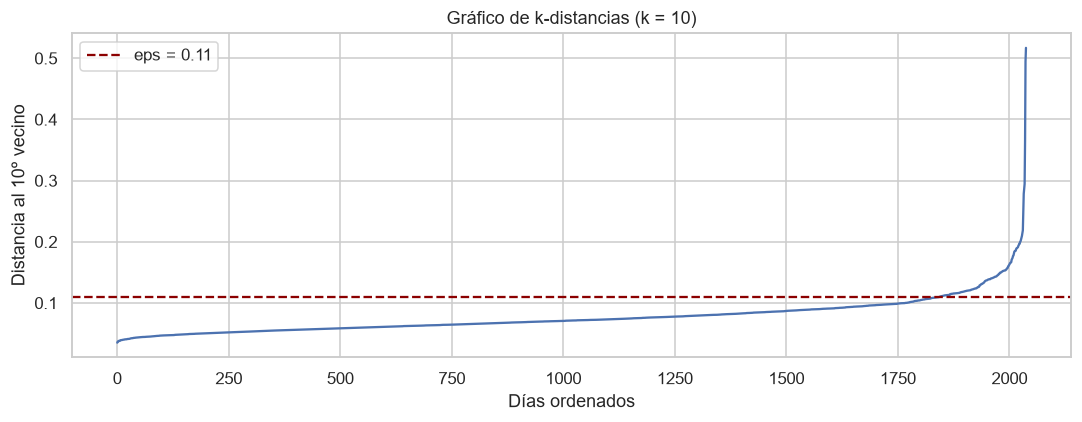

,grupos,días_ruido
eps,,
0.06,6,1118
0.08,5,339
0.10,1,119
0.11,1,78
0.13,1,41
0.15,1,21


In [11]:
MIN_SAMPLES = 10
vecinos = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(formas)
k_distancia = np.sort(vecinos.kneighbors(formas)[0][:, -1])

# cómo cambia el resultado con eps
pruebas_eps = []
for eps in [0.06, 0.08, 0.10, 0.11, 0.13, 0.15]:
    etiquetas = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(formas)
    pruebas_eps.append({"eps": eps, "grupos": len(set(etiquetas) - {-1}), "días_ruido": (etiquetas == -1).sum()})
pruebas_eps = pd.DataFrame(pruebas_eps).set_index("eps")

EPS = 0.11
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(k_distancia)
ax.axhline(EPS, color="darkred", ls="--", label=f"eps = {EPS}")
ax.set(title=f"Gráfico de k-distancias (k = {MIN_SAMPLES})", xlabel="Días ordenados", ylabel=f"Distancia al {MIN_SAMPLES}º vecino")
ax.legend()
guardar("k_distancias_dbscan")
pruebas_eps

La tabla muestra el dilema de DBSCAN con estos datos:

- Con `eps` chico (0,06–0,08) encuentra varios grupos, pero deja como ruido entre el 17 % y el 55 % de los días: no sirve.
- Con `eps` ≥ 0,10 todos los días "normales" quedan en **un único grupo** y solo quedan afuera los aislados.

**DBSCAN no encuentra grupos separados** porque no los hay: como mostró PCA, los días forman una nube continua que va del invierno al verano y del hábil al no hábil, sin zonas vacías entre medio. K-means igual la divide en cuatro porque está obligado a hacerlo. Las dos visiones son complementarias: K-means da los **perfiles típicos** útiles para programar; DBSCAN dice que entre ellos hay un continuo.

Por eso DBSCAN se usa para lo que mejor hace, **detectar días atípicos**. Se elige `eps = 0,11`, en la zona donde la curva de k-distancias empieza a dispararse: deja afuera al ~4 % de los días más aislados.

In [12]:
info["dbscan"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(formas)
info["atipico"] = info["dbscan"] == -1
print(f"Grupos densos: {info.loc[~info.atipico, 'dbscan'].nunique()} | días atípicos (ruido): {info.atipico.sum()} ({info.atipico.mean():.1%})")

# ¿de qué grupo de K-means vienen los días atípicos?
pd.crosstab(info["grupo"], info["atipico"].map({True: "atípico", False: "normal"})).reindex(ORDEN)

Grupos densos: 1 | días atípicos (ruido): 78 (3.8%)


atipico,atípico,normal
grupo,,
Hábil de invierno,3,844
Hábil de verano,13,467
No hábil de invierno,6,422
No hábil de verano,56,227


In [13]:
# lista de días atípicos
DIAS_ES = dict(enumerate(["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]))
atipicos = info[info.atipico].assign(dia=lambda d: d["dia_semana"].map(DIAS_ES))
atipicos[["dia", "tipo_dia", "grupo", "temp_max", "demanda_media"]].round(1)

,dia,tipo_dia,grupo,temp_max,demanda_media
2021-01-30,sáb,no_habil,No hábil de verano,24.0,14080.3
2021-02-21,dom,no_habil,No hábil de invierno,27.6,13819.8
2021-08-08,dom,no_habil,No hábil de invierno,17.2,13859.9
2021-10-31,dom,no_habil,No hábil de verano,22.6,13549.5
2021-11-16,mar,habil,No hábil de verano,21.0,14506.5
...,...,...,...,...,...
2026-03-21,sáb,no_habil,No hábil de verano,23.8,14442.9
2026-04-03,vie,no_habil,Hábil de verano,29.8,16037.2
2026-07-03,vie,habil,Hábil de invierno,9.0,21071.1
2026-07-15,mié,habil,Hábil de invierno,17.0,17186.5


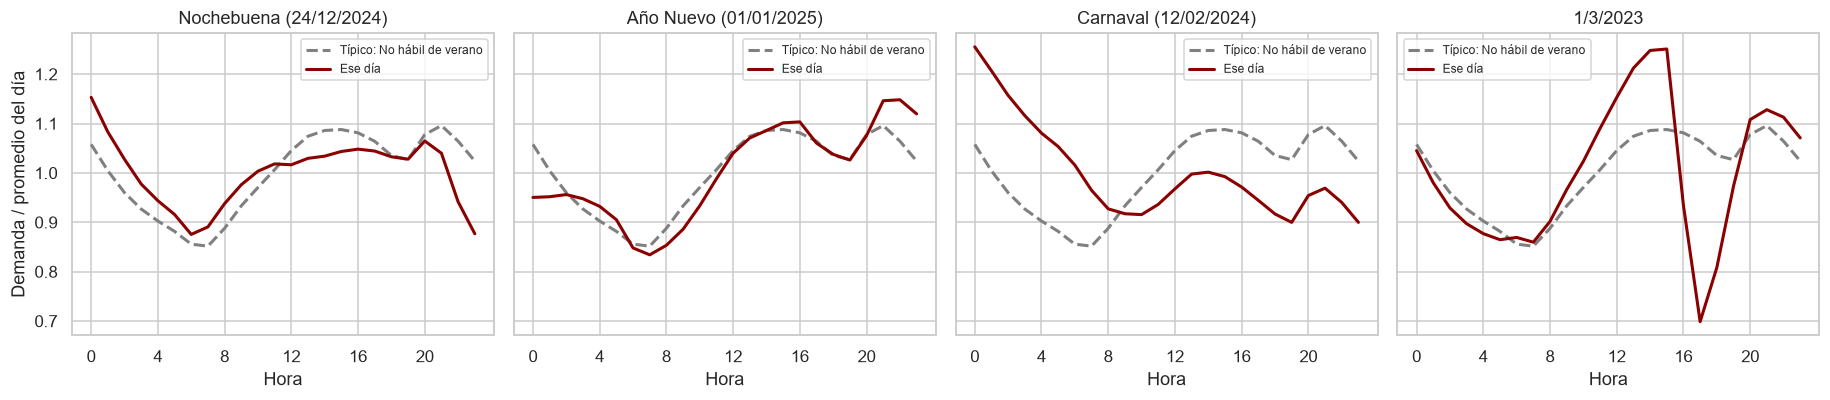

In [14]:
# ¿cómo se ven? algunos días atípicos contra la curva típica de su grupo
casos = {"Nochebuena (24/12/2024)": "2024-12-24", "Año Nuevo (01/01/2025)": "2025-01-01",
         "Carnaval (12/02/2024)": "2024-02-12", "1/3/2023": "2023-03-01"}
casos = {k: v for k, v in casos.items() if info.loc[v, "atipico"]}   # solo los que DBSCAN marcó como ruido

fig, axes = plt.subplots(1, len(casos), figsize=(4.2 * len(casos), 3.8), sharey=True)
for ax, (titulo, fecha) in zip(np.atleast_1d(axes), casos.items()):
    grupo = info.loc[fecha, "grupo"]
    ax.plot(centroides.loc[grupo].values, color="gray", lw=2, ls="--", label=f"Típico: {grupo}")
    ax.plot(formas.loc[fecha].values, color="darkred", lw=2, label="Ese día")
    ax.set(title=titulo, xlabel="Hora", xticks=range(0, 24, 4))
    ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("Demanda / promedio del día")
guardar("dias_atipicos")

**Los 78 días atípicos se pueden explicar casi todos:**

- **Fiestas de fin de año (15 días):** el 24/12, el 31/12 y el 1/1 de todos los años. En Nochebuena y Fin de Año la demanda cae fuerte a la noche, durante los festejos. El 1 de enero arranca tarde y termina alto.
- **Feriados largos de verano:** carnavales (2022, 2024 y 2026) y Semana Santa (2024 y 2026). Son días no hábiles en plena temporada de calor y vacaciones.
- **Días de calor extremo (8)** y, en general, días de verano: 67 de los 78 atípicos caen entre noviembre y marzo, y 55 son no hábiles. Los fines de semana de verano son los días con forma más variable, porque depende mucho de cuánto calor hace y de qué hace la gente.
- **El 1/3/2023:** la curva se derrumba entre las 16 y las 17 h y se recupera de a poco. Coincide con el **apagón masivo** de ese día. DBSCAN lo detectó sin ninguna información externa.

Estos son los días en que un modelo entrenado con días "normales" puede fallar más. En el pronóstico real, un operador los trata aparte: las fiestas y los feriados se programan con criterio propio, y un apagón no se puede pronosticar.

## 8. Comparación de métricas

Las métricas internas de clustering (no necesitan etiquetas "verdaderas"):

- **Silueta:** más alto es mejor (−1 a 1).
- **Davies-Bouldin:** cuánto se superponen los grupos; más bajo es mejor.
- **Calinski-Harabasz:** separación entre grupos sobre dispersión dentro de cada grupo; más alto es mejor.

Para DBSCAN se calculan sin los puntos de ruido. Si DBSCAN encuentra un solo grupo denso, estas métricas no se pueden calcular: todas comparan grupos entre sí.

In [15]:
def metricas(nombre, X, etiquetas):
    """Métricas internas de clustering; None si hay menos de 2 grupos."""
    if len(set(etiquetas)) < 2:
        return {"método": nombre, "grupos": len(set(etiquetas)), "silueta": None, "davies_bouldin": None, "calinski_harabasz": None}
    return {
        "método": nombre,
        "grupos": len(set(etiquetas)),
        "silueta": silhouette_score(X, etiquetas),
        "davies_bouldin": davies_bouldin_score(X, etiquetas),
        "calinski_harabasz": calinski_harabasz_score(X, etiquetas),
    }


normales = ~info["atipico"].values
pd.DataFrame([
    metricas(f"K-means (k = {K})", formas, info["cluster"]),
    metricas(f"K-means (k = {K}), sin los días atípicos", formas[normales], info.loc[normales, "cluster"]),
    metricas(f"DBSCAN (eps = {EPS}), sin ruido", formas[normales], info.loc[normales, "dbscan"]),
]).set_index("método").round(3)

,grupos,silueta,davies_bouldin,calinski_harabasz
método,,,,
K-means (k = 4),4,0.367,1.114,1120.240
"K-means (k = 4), sin los días atípicos",4,0.369,1.091,1156.544
"DBSCAN (eps = 0.11), sin ruido",1,NaN,NaN,NaN


- Las métricas de K-means **mejoran levemente sin los días atípicos** (silueta 0,367 → 0,369; Calinski-Harabasz 1.120 → 1.157). Es lo esperable: esos días están lejos de todos los grupos y empeoran las métricas.
- Para DBSCAN no se pueden calcular: con `eps` = 0,11 deja un solo grupo denso, y todas las métricas internas necesitan al menos dos grupos para comparar.

Las métricas confirman la lectura de las secciones anteriores: hay estructura (silueta claramente positiva), pero los grupos no están separados por huecos.

## 9. Conclusiones

**Días típicos (K-means, k = 4).** Sin decirle qué día es hábil ni en qué estación está, el algoritmo encontró cuatro perfiles de carga con sentido físico:

| Grupo | Días | Forma de la curva |
|---|---|---|
| Hábil de invierno | 847 | Dos picos: mañana (~11 h) y noche (~20 h) |
| Hábil de verano | 480 | Un pico de tarde (14–16 h), por el aire acondicionado |
| No hábil de invierno | 428 | Sin pico de mañana; pico de noche muy marcado |
| No hábil de verano | 283 | La más plana; incluye días hábiles de vacaciones de verano |

- **Dos ejes explican la forma de un día:** la estación (en realidad, la **temperatura**) y la **actividad laboral**. PCA lo muestra con dos componentes que explican el 79 % de la variación.
- **Los grupos los define el clima más que el calendario:** los meses de transición se reparten según haga calor o no, y los días hábiles de enero se comportan como fines de semana.
- **No hay grupos separados, sino un continuo** (silueta ~0,37, DBSCAN con un solo grupo denso). Los cuatro grupos son perfiles representativos de ese continuo, útiles para programar el despacho, no categorías cerradas.

**Días atípicos (DBSCAN).** El 4 % de los días no se parece a ningún otro: fiestas de fin de año, feriados largos de verano, días de calor extremo y el apagón del 1/3/2023.

**Conexión con el modelo supervisado.**

- Confirma las decisiones del notebook 02: la interacción **hora × temperatura** es la estructura central de los datos, y por eso los modelos de árboles le ganan a la regresión lineal.
- Muestra una limitación de usar el tipo de día de CAMMESA como única variable de calendario: los días hábiles de vacaciones de verano tienen otra forma. Una variable de "vacaciones de verano" o el grupo de K-means como variable podrían mejorar el modelo, pero con un cuidado: el grupo de un día se calcula con su propia curva, que no se conoce de antemano. Habría que predecirlo con el calendario y el pronóstico del tiempo.
- Los días atípicos son candidatos a tratarse aparte en el pronóstico (fiestas, feriados largos), y a excluirse o marcarse al entrenar (el apagón).

**Limitaciones.**

- Se agrupó la **forma** de la curva; dos días con la misma forma pero niveles muy distintos quedan juntos. Es una decisión deliberada, para que la tendencia de crecimiento no domine el resultado.
- K-means asume grupos más o menos esféricos y de tamaño parecido, y los datos son un continuo. Los días de transición (otoño y primavera) se asignan al grupo más cercano aunque estén entre dos.
- `eps` de DBSCAN se eligió con un criterio visual (k-distancias). Otro valor cambia la cantidad de días atípicos, aunque no la conclusión de que no hay grupos separados.